# 02 - التحويلات الهندسية للصور

يغطي هذا الدفتر موضوعات LAB3: القص (ROI)، تغيير الحجم، التدوير، الإزاحة، والقلب. يطلب من المستخدم رفع صورة أو عدة صور، ويعرض النتائج للمقارنة، ثم يحفظها داخل Google Drive.

## أهداف الدفتر

- رفع صورة أو عدة صور من الجهاز.
- تنفيذ Center Crop بطريقة تناسب أي حجم للصورة.
- المقارنة بين التكبير والتصغير وطرق Interpolation.
- تدوير الصورة بزوايا موجبة وسالبة.
- إزاحة الصورة أفقيًا وعموديًا.
- قلب الصورة أفقيًا وعموديًا.
- تجربة الأدوات بصورة تفاعلية.
- حفظ النتائج تلقائيًا في Google Drive.

## 1. استيراد المكتبات وربط Google Drive

عند تشغيل الدفتر داخل Colab سيطلب السماح بالوصول إلى Drive. وعند تشغيله خارج Colab يستخدم مجلدًا محليًا للاختبار.

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    PROJECT_ROOT = Path(
        '/content/drive/MyDrive/'
        'VisionStudio_Android_ImageProcessing'
    )
except ImportError:
    IN_COLAB = False
    PROJECT_ROOT = Path('VisionStudio_Android_ImageProcessing')

INPUT_DIR = PROJECT_ROOT / '02_Data/Images/Input'
OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Images/02_Geometric_Transformations'
)

INPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Running in Colab:', IN_COLAB)
print('Input directory:', INPUT_DIR)
print('Output directory:', OUTPUT_DIR)

Mounted at /content/drive
Running in Colab: True
Input directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input
Output directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/02_Geometric_Transformations


## 2. دوال العرض والمعالجة

وضع العمليات داخل دوال يجعل إعادة استخدامها في الصور والفيديو وتطبيق Android أسهل.

In [2]:
def to_rgb(image):
    if image.ndim == 2:
        return image
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def show_comparison(results, columns=3, figure_width=16):
    items = list(results.items())
    rows = int(np.ceil(len(items) / columns))
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(figure_width, rows * 4.5),
        squeeze=False
    )

    for axis, (title, image) in zip(axes.ravel(), items):
        axis.imshow(to_rgb(image), cmap='gray' if image.ndim == 2 else None)
        axis.set_title(title)
        axis.axis('off')

    for axis in axes.ravel()[len(items):]:
        axis.axis('off')

    plt.tight_layout()
    plt.show()


def center_crop(image, width_ratio=0.60, height_ratio=0.60):
    height, width = image.shape[:2]
    crop_width = max(1, int(width * width_ratio))
    crop_height = max(1, int(height * height_ratio))
    x1 = (width - crop_width) // 2
    y1 = (height - crop_height) // 2
    x2 = x1 + crop_width
    y2 = y1 + crop_height
    return image[y1:y2, x1:x2].copy()


def crop_by_percent(image, x_start, x_end, y_start, y_end):
    height, width = image.shape[:2]
    x1 = int(width * x_start / 100)
    x2 = int(width * x_end / 100)
    y1 = int(height * y_start / 100)
    y2 = int(height * y_end / 100)
    return image[y1:y2, x1:x2].copy()


def resize_by_scale(image, scale, interpolation):
    height, width = image.shape[:2]
    new_width = max(1, int(width * scale))
    new_height = max(1, int(height * scale))
    return cv2.resize(
        image, (new_width, new_height), interpolation=interpolation
    )


def rotate_image(image, angle, scale=1.0):
    height, width = image.shape[:2]
    center = (width // 2, height // 2)
    matrix = cv2.getRotationMatrix2D(center, angle, scale)
    return cv2.warpAffine(
        image, matrix, (width, height),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0)
    )


def translate_image(image, tx, ty):
    height, width = image.shape[:2]
    matrix = np.float32([[1, 0, tx], [0, 1, ty]])
    return cv2.warpAffine(
        image, matrix, (width, height),
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0)
    )


def flip_image(image, mode):
    # mode=1 أفقي، mode=0 عمودي، mode=-1 كلاهما
    return cv2.flip(image, mode)

## 3. رفع صورة أو عدة صور

يمكن تحديد عدة صور من نافذة الرفع. تُحفظ كل صورة أصلية داخل مجلد `02_Data/Images/Input`.

In [3]:
# ============================================================
# قراءة الصور من Google Drive
# والرفع الاختياري عند إضافة صور جديدة
# ============================================================

# اجعلها True فقط عند إضافة صور جديدة
UPLOAD_NEW_FILES = False

SUPPORTED_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

uploaded_images = {}


# ============================================================
# 1. قراءة الصور الموجودة في مجلد Input
# ============================================================

existing_image_paths = sorted([
    path
    for path in INPUT_DIR.iterdir()
    if (
        path.is_file()
        and path.suffix.lower()
        in SUPPORTED_EXTENSIONS
    )
])

for image_path in existing_image_paths:

    loaded_image = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    if loaded_image is None:
        print(
            f"تعذر قراءة الصورة: "
            f"{image_path.name}"
        )
        continue

    uploaded_images[
        image_path.name
    ] = loaded_image


print(
    "عدد الصور الموجودة في Drive:",
    len(uploaded_images)
)


# ============================================================
# 2. رفع صور جديدة عند الحاجة فقط
# ============================================================

if IN_COLAB and UPLOAD_NEW_FILES:

    from google.colab import files

    print("اختر صورة أو عدة صور:")

    uploaded_files = files.upload()

    for file_name, file_data in uploaded_files.items():

        image_array = np.frombuffer(
            file_data,
            dtype=np.uint8
        )

        loaded_image = cv2.imdecode(
            image_array,
            cv2.IMREAD_COLOR
        )

        if loaded_image is None:
            print(
                f"تعذر قراءة الملف: "
                f"{file_name}"
            )
            continue

        safe_file_name = Path(
            file_name
        ).name

        input_path = (
            INPUT_DIR / safe_file_name
        )

        save_success = cv2.imwrite(
            str(input_path),
            loaded_image
        )

        if not save_success:
            print(
                f"فشل حفظ الصورة: "
                f"{safe_file_name}"
            )
            continue

        uploaded_images[
            safe_file_name
        ] = loaded_image

        print(
            f"تمت إضافة الصورة: "
            f"{safe_file_name}"
        )


# ============================================================
# 3. التحقق من وجود صور
# ============================================================

if not uploaded_images:

    raise ValueError(
        "لا توجد صور داخل مجلد Input.\n"
        "ضع صورة في المجلد أو اجعل:\n"
        "UPLOAD_NEW_FILES = True"
    )


# ============================================================
# 4. عرض الصور المتاحة
# ============================================================

print(
    f"\nعدد الصور الجاهزة للمعالجة: "
    f"{len(uploaded_images)}"
)

for index, (
    file_name,
    loaded_image
) in enumerate(
    uploaded_images.items(),
    start=1
):

    print(
        f"{index}. {file_name} "
        f"- الأبعاد: {loaded_image.shape}"
    )

عدد الصور الموجودة في Drive: 4

عدد الصور الجاهزة للمعالجة: 4
1. R.jpeg - الأبعاد: (736, 736, 3)
2. balloons.jpg - الأبعاد: (547, 602, 3)
3. children.jpeg - الأبعاد: (774, 1376, 3)
4. coins.jpg - الأبعاد: (390, 400, 3)


## 4. اختيار الصورة المستخدمة في العرض التفاعلي

تُعالج جميع الصور لاحقًا، لكن أول صورة تُستخدم في المقارنات والأدوات التفاعلية.

Selected image: R.jpeg
Width: 736
Height: 736


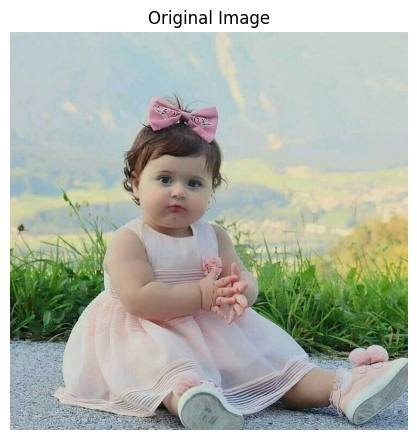

In [4]:
selected_name = next(iter(uploaded_images))
image = uploaded_images[selected_name]
height, width = image.shape[:2]

print('Selected image:', selected_name)
print('Width:', width)
print('Height:', height)

show_comparison({'Original Image': image}, columns=1, figure_width=8)

## 5. القص - Region of Interest (ROI)

يتم تخزين الصورة على شكل `image[y1:y2, x1:x2]`. هنا نقص 60% من منتصف الصورة حتى يعمل المثال مع أي أبعاد.

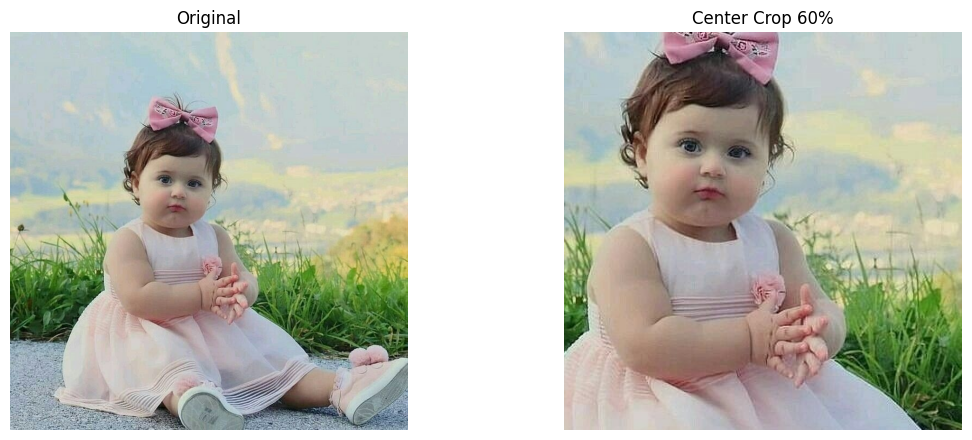

Original shape: (736, 736, 3)
Cropped shape: (441, 441, 3)


In [5]:
cropped = center_crop(image, width_ratio=0.60, height_ratio=0.60)

show_comparison(
    {
        'Original': image,
        'Center Crop 60%': cropped
    },
    columns=2,
    figure_width=12
)

print('Original shape:', image.shape)
print('Cropped shape:', cropped.shape)

## 6. تغيير الحجم - Resize

نستخدم `INTER_CUBIC` عند التكبير للحصول على نتيجة أنعم، و`INTER_AREA` عند التصغير لتقليل فقد التفاصيل.

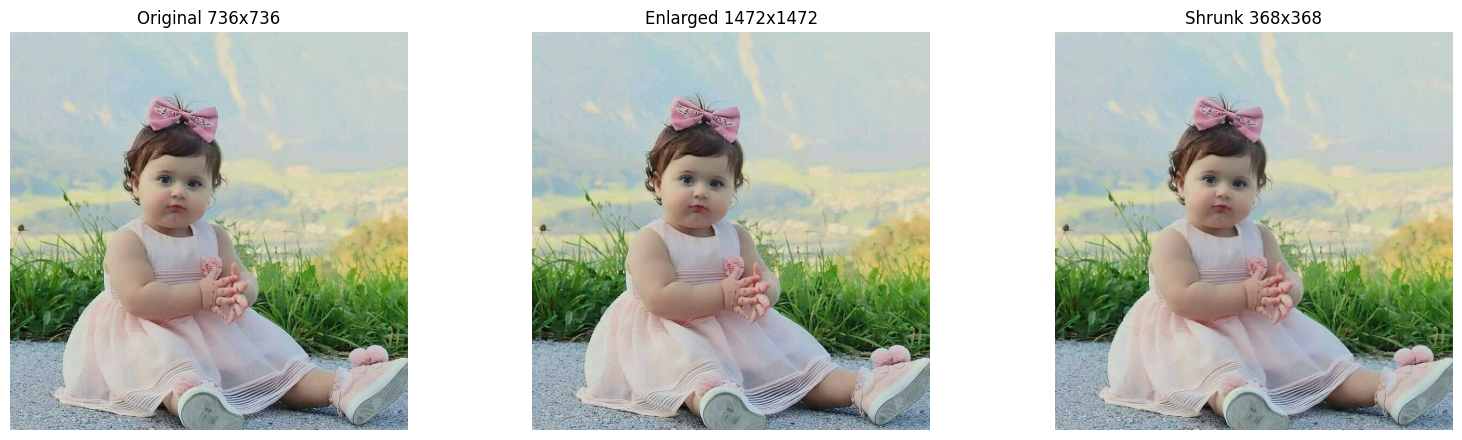

In [6]:
enlarged = resize_by_scale(image, 2.0, cv2.INTER_CUBIC)
shrunk = resize_by_scale(image, 0.5, cv2.INTER_AREA)

show_comparison(
    {
        f'Original {width}x{height}': image,
        f'Enlarged {enlarged.shape[1]}x{enlarged.shape[0]}': enlarged,
        f'Shrunk {shrunk.shape[1]}x{shrunk.shape[0]}': shrunk
    },
    columns=3
)

## 7. التدوير والإزاحة والقلب

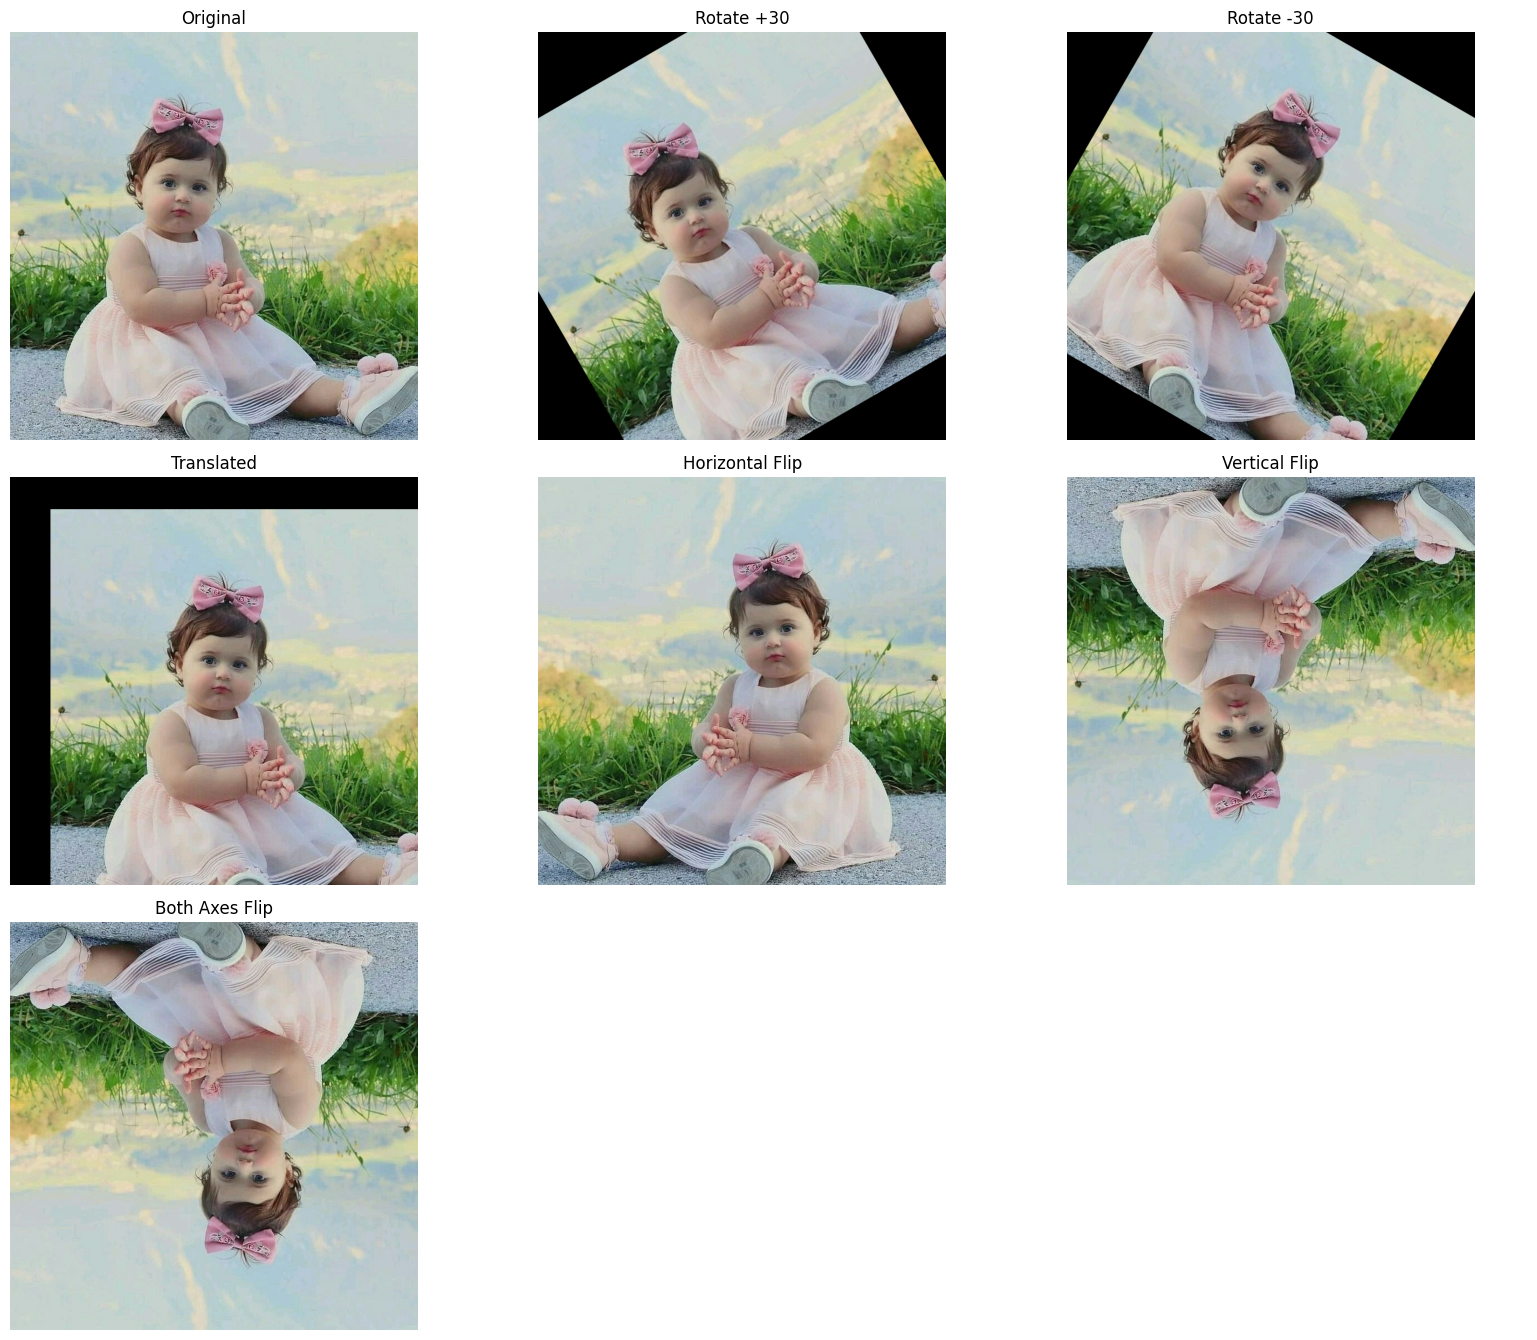

In [7]:
rotated_positive = rotate_image(image, 30)
rotated_negative = rotate_image(image, -30)
translated = translate_image(
    image, tx=int(width * 0.10), ty=int(height * 0.08)
)
flipped_horizontal = flip_image(image, 1)
flipped_vertical = flip_image(image, 0)
flipped_both = flip_image(image, -1)

show_comparison(
    {
        'Original': image,
        'Rotate +30': rotated_positive,
        'Rotate -30': rotated_negative,
        'Translated': translated,
        'Horizontal Flip': flipped_horizontal,
        'Vertical Flip': flipped_vertical,
        'Both Axes Flip': flipped_both
    },
    columns=3
)

## 8. أداة تفاعلية للتدوير والتكبير والإزاحة

حرّك القيم لمشاهدة التأثير مباشرة على الصورة.

In [8]:
try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print('الأدوات التفاعلية متاحة تلقائيًا داخل Google Colab.')

def interactive_transform(angle=0, scale=1.0, tx=0, ty=0):
    result = rotate_image(image, angle, scale)
    result = translate_image(result, tx, ty)

    show_comparison(
        {
            'Original': image,
            f'Angle={angle}, Scale={scale:.2f}, Move=({tx}, {ty})': result
        },
        columns=2,
        figure_width=12
    )

if WIDGETS_AVAILABLE:
    transform_controls = widgets.interactive(
        interactive_transform,
        angle=widgets.IntSlider(
            value=0, min=-180, max=180, step=5, description='Angle'
        ),
        scale=widgets.FloatSlider(
            value=1.0, min=0.25, max=2.0, step=0.05, description='Scale'
        ),
        tx=widgets.IntSlider(
            value=0, min=-width // 2, max=width // 2,
            step=5, description='Move X'
        ),
        ty=widgets.IntSlider(
            value=0, min=-height // 2, max=height // 2,
            step=5, description='Move Y'
        )
    )
    display(transform_controls)

interactive(children=(IntSlider(value=0, description='Angle', max=180, min=-180, step=5), FloatSlider(value=1.…

## 9. أداة تفاعلية لاختيار منطقة القص

القيم تمثل النسبة المئوية من عرض الصورة وارتفاعها. يجب أن تكون بداية النطاق أصغر من نهايته.

In [9]:
def interactive_crop(x_range=(20, 80), y_range=(20, 80)):
    x_start, x_end = x_range
    y_start, y_end = y_range
    result = crop_by_percent(
        image, x_start, x_end, y_start, y_end
    )

    show_comparison(
        {
            'Original': image,
            f'Crop X={x_range}%, Y={y_range}%': result
        },
        columns=2,
        figure_width=12
    )

if WIDGETS_AVAILABLE:
    crop_controls = widgets.interactive(
        interactive_crop,
        x_range=widgets.IntRangeSlider(
            value=[20, 80], min=0, max=100, step=1,
            description='X Range'
        ),
        y_range=widgets.IntRangeSlider(
            value=[20, 80], min=0, max=100, step=1,
            description='Y Range'
        )
    )
    display(crop_controls)
else:
    print('شغّل هذه الخلية داخل Colab لعرض أداة القص التفاعلية.')

interactive(children=(IntRangeSlider(value=(20, 80), description='X Range'), IntRangeSlider(value=(20, 80), de…

## 10. معالجة جميع الصور وحفظ النتائج

تُنشأ لكل صورة مجلد مستقل حتى لا تختلط النتائج عند رفع عدة صور.

In [10]:
saved_files = []

for file_name, source_image in uploaded_images.items():
    stem = Path(file_name).stem
    image_output_dir = OUTPUT_DIR / stem
    image_output_dir.mkdir(parents=True, exist_ok=True)

    source_height, source_width = source_image.shape[:2]
    results = {
        '00_original.png': source_image,
        '01_center_crop.png': center_crop(source_image),
        '02_enlarged_cubic.png': resize_by_scale(
            source_image, 2.0, cv2.INTER_CUBIC
        ),
        '03_shrunk_area.png': resize_by_scale(
            source_image, 0.5, cv2.INTER_AREA
        ),
        '04_rotated_positive_30.png': rotate_image(source_image, 30),
        '05_rotated_negative_30.png': rotate_image(source_image, -30),
        '06_translated.png': translate_image(
            source_image,
            int(source_width * 0.10),
            int(source_height * 0.08)
        ),
        '07_flip_horizontal.png': flip_image(source_image, 1),
        '08_flip_vertical.png': flip_image(source_image, 0),
        '09_flip_both.png': flip_image(source_image, -1)
    }

    for output_name, result_image in results.items():
        output_path = image_output_dir / output_name
        if not cv2.imwrite(str(output_path), result_image):
            raise IOError(f'فشل حفظ الصورة: {output_path}')
        saved_files.append(output_path)

print(f'تم حفظ {len(saved_files)} ملفًا بنجاح.')
print('مجلد النتائج:', OUTPUT_DIR)
for path in saved_files:
    print('-', path.name)

تم حفظ 40 ملفًا بنجاح.
مجلد النتائج: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/02_Geometric_Transformations
- 00_original.png
- 01_center_crop.png
- 02_enlarged_cubic.png
- 03_shrunk_area.png
- 04_rotated_positive_30.png
- 05_rotated_negative_30.png
- 06_translated.png
- 07_flip_horizontal.png
- 08_flip_vertical.png
- 09_flip_both.png
- 00_original.png
- 01_center_crop.png
- 02_enlarged_cubic.png
- 03_shrunk_area.png
- 04_rotated_positive_30.png
- 05_rotated_negative_30.png
- 06_translated.png
- 07_flip_horizontal.png
- 08_flip_vertical.png
- 09_flip_both.png
- 00_original.png
- 01_center_crop.png
- 02_enlarged_cubic.png
- 03_shrunk_area.png
- 04_rotated_positive_30.png
- 05_rotated_negative_30.png
- 06_translated.png
- 07_flip_horizontal.png
- 08_flip_vertical.png
- 09_flip_both.png
- 00_original.png
- 01_center_crop.png
- 02_enlarged_cubic.png
- 03_shrunk_area.png
- 04_rotated_positive_30.png
- 05_rotated_negative_30.png
- 06_translated.png
- 07_fl

## 11. الربط بتطبيق Android

ستُنقل الخوارزميات لاحقًا إلى Kotlin باستخدام:

- `Imgproc.resize()` لتغيير الحجم.
- `Imgproc.getRotationMatrix2D()` و`Imgproc.warpAffine()` للتدوير.
- `Imgproc.warpAffine()` للإزاحة.
- `Core.flip()` للقلب.
- اختيار ROI من `Mat` لتنفيذ القص.

وسيستخدم تطبيق Android القيم نفسها التي تم اختبارها في هذا الدفتر.

## 12. تمارين مقترحة

1. ارفع صورتين بأبعاد مختلفة وتأكد أن Center Crop يعمل معهما.
2. قارن `INTER_CUBIC` و`INTER_LINEAR` عند تكبير الصورة.
3. جرّب تدوير الصورة بزاوية 45 و90 و180 درجة.
4. لاحظ المناطق السوداء التي تظهر بعد التدوير والإزاحة، وفكّر في طرق معالجتها.